In [1]:
import rasterio
import os
from tqdm import tqdm
import numpy as np

In [2]:
#|export
import pathlib
def save_raster(
    img:np.ndarray , # ndarray image
    number_of_bands: int , #number of  bands
    transf:tuple ,#transform function of the raster
    paths:str ,#save path raster
    tiff_name:str ,#name of specific file
    crs_img:rasterio.crs.CRS,
    ):  
    
    '''
    Function to save raster in requested path

    '''

    savedir=pathlib.Path(paths)
    savedir.mkdir(parents=True,exist_ok=True)


    with rasterio.open(savedir /tiff_name, 
                                   'w',
                                   driver='GTiff',
                                   height=img.shape[1],
                                   width=img.shape[2],
                                   count=number_of_bands,
                                   dtype=img.dtype,
                                   crs=crs_img,
                                   nodata=None, # change if data has nodata value
                                   transform=transf) as dst:

            for n in np.arange(0,number_of_bands):
                  dst.write(img[n,:,:],int(n+1))   
                    
    return None

In [5]:
def ntf_to_tif(
    input_dir: str , #the direcotry where images are stored
    output_dir: str, #the directory where the results images to be saved
):
    for filename in tqdm(os.listdir(input_dir), desc="Processing rasters"):
    # for filename in os.listdir(input_dir):
        print(filename)
        # process only files with .NTF extension
            
        output_filename = os.path.splitext(filename)[0] + ".tif"
        input_path = os.path.join(input_dir, filename)

        if not os.path.isfile(input_path) or not filename.lower().endswith(".ntf"):
            print(f"file {filename} is not .NTF, skipping")
            continue
       
        output_path = os.path.join(output_dir, output_filename)  
            
        os.makedirs(os.path.dirname(output_path), exist_ok=True)
        print(f"reading {filename}")
        src = rasterio.open(input_path)
        
        arr=src.read()
        print(arr.shape)
        
        save_raster(
            img= arr,
            number_of_bands=3,
            transf=src.transform,
            paths=output_dir,
            tiff_name=output_filename,
            crs_img=src.crs)
        print(f"saved to: {output_path}")
        


In [6]:
ntf_to_tif(
    input_dir="/home/jovyan/work/imagery/test_DONT_REMOVE/test_brian/run5/6809525113733725304",
    output_dir="/home/jovyan/work/imagery/test_DONT_REMOVE/test_brian/test_ntf")

Processing rasters:   0%|          | 0/7 [00:00<?, ?it/s]

19JAN16050556-S3DS-200009643316_01_P001.IMD
file 19JAN16050556-S3DS-200009643316_01_P001.IMD is not .NTF, skipping
19JAN16050556-S3DS-200009643316_01_P001.TIL
file 19JAN16050556-S3DS-200009643316_01_P001.TIL is not .NTF, skipping
19JAN16050556-S3DS-200009643316_01_P001_README.TXT
file 19JAN16050556-S3DS-200009643316_01_P001_README.TXT is not .NTF, skipping
19JAN16050556-S3DS-200009643316_01_P001.XML
file 19JAN16050556-S3DS-200009643316_01_P001.XML is not .NTF, skipping
19JAN16050556-S3DS-200009643316_01_P001-BROWSE.JPG
file 19JAN16050556-S3DS-200009643316_01_P001-BROWSE.JPG is not .NTF, skipping
LICENSE.TXT
file LICENSE.TXT is not .NTF, skipping
19JAN16050556-S3DS-200009643316_01_P001.NTF
reading 19JAN16050556-S3DS-200009643316_01_P001.NTF
(3, 6144, 11264)


Processing rasters: 100%|██████████| 7/7 [00:03<00:00,  1.94it/s]

saved to: /home/jovyan/work/imagery/test_DONT_REMOVE/test_brian/test_ntf/19JAN16050556-S3DS-200009643316_01_P001.tif


In [34]:
src=rasterio.open("/home/jovyan/work/imagery/test_DONT_REMOVE/test_brian/run3/RES_NTF/6806692943581418772_1_0.tif")

In [35]:
src.count

3

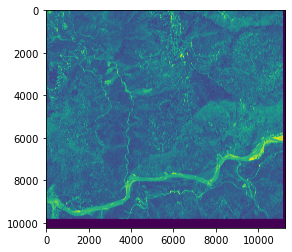

In [8]:
src=rasterio.open("/home/jovyan/work/imagery/test_DONT_REMOVE/test_brian/run5/NTF/dhankuta_24052023WV02RGB_NTF_ENH/23MAY24050015-S3DS-200009643397_01_P001.NTF")
test=src.read()
import matplotlib.pyplot as plt

plt.imshow(test[0])

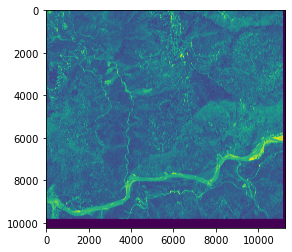

In [9]:
src=rasterio.open("/home/jovyan/work/imagery/test_DONT_REMOVE/test_brian/run5/output/dhankuta_24052023WV02RGB_NTF_ENH/23MAY24050015-S3DS-200009643397_01_P001.tif")
test=src.read()
import matplotlib.pyplot as plt

plt.imshow(test[0])